# 01 · Data quality of a 13-year PV monitoring record

**System:** NREL PVDAQ system 4, a 1 kW array of five Sanyo HIT (mono-Si heterojunction) modules on a fixed rack
(40° tilt, due south) at NREL in Golden, Colorado. One-minute data, January 2010 – February 2023.

Field PV data are messy: sensors fail, loggers go offline, inverters trip. Before any performance or
degradation number can be trusted, every reading has to be checked. This notebook builds and applies an
automated quality-control (QC) pipeline and documents what it finds.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import data, qc

FIG = ROOT / "figures"; RES = ROOT / "results"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
meta = json.load(open(ROOT / "metadata/system_4.json"))
meta["System"], meta["Mount"]["Mount 0"]["tilt"], meta["Modules"]["Module 0"]["model"]

({'system_id': 4,
  'site_id': 15,
  'public_name': '[4] NREL x-Si -1',
  'area': '5.896',
  'power': '1.0',
  'started_on': '2007-08-26 06:00:00',
  'ended_on': '',
  'comments': 'HIP'},
 '40.0',
 'hip-200ba3')

## 1. Load the data

The raw data are ~4,200 daily CSV files on the public OEDI data lake. `src/data.py` downloads and merges
them into one parquet file (run once, ~1 GB download):

```python
data.download_system(4, "data/raw")
data.consolidate("data/raw", "data/system4_1min.parquet")
```

Below, the record is put on a complete 1-minute time grid so that missing minutes become explicit gaps.

In [2]:
raw = data.load(ROOT / "data/system4_1min.parquet")
grid = pd.date_range(raw.index.min().normalize(),
                     raw.index.max().normalize() + pd.Timedelta("1D") - pd.Timedelta("1min"), freq="1min")
df = raw.reindex(grid)
print(f"{len(df):,} minutes, {df.index.min()} to {df.index.max()}")
df.describe().T.round(1)

6,893,280 minutes, 2010-01-21 00:00:00 to 2023-02-28 23:59:00


,count,mean,std,min,25%,50%,75%,max
ac_power,5990146.0,160.9,267.7,-1786.7,2.9,3.2,217.2,2101.9
dc_power,5990148.0,175.5,291.6,-7999.0,0.0,0.0,244.4,9043.4
poa,5772513.0,163.4,804.0,-7999.0,-2.9,1.4,361.5,3624.7
t_amb,5990143.0,11.6,299.3,-7999.0,3.9,11.7,19.5,708281.0
t_mod1,5973592.0,-681.7,2259.2,-7999.0,0.7,12.2,24.0,1188.0
t_mod2,5791347.0,-1007.4,2674.8,-7999.0,-0.8,11.3,23.4,2011.0
t_mod3,5823387.0,-773.5,2388.7,-7999.0,0.4,12.0,24.0,263.0


The summary already shows problems: module temperatures with a minimum of −7,999 °C (the PVDAQ
"no data" code), an ambient temperature of 708,281 °C, AC power of −1,787 W and POA irradiance of
3,625 W/m² (more than twice what the sun can deliver).

## 2. Data availability

Overall: 86.9%


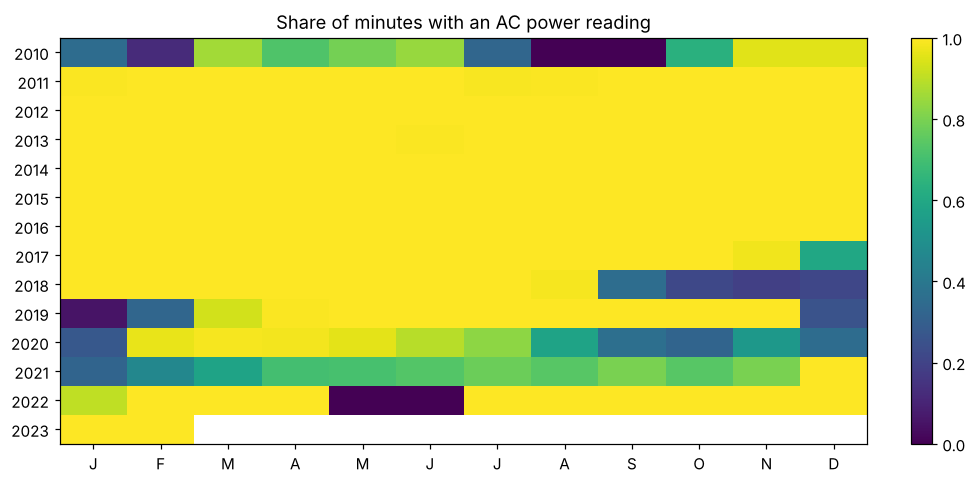

In [3]:
avail = df.ac_power.notna().groupby([df.index.year, df.index.month]).mean().unstack()
fig, ax = plt.subplots(figsize=(9, 4.5))
im = ax.imshow(avail.values, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(12), ["J","F","M","A","M","J","J","A","S","O","N","D"])
ax.set_yticks(range(len(avail)), avail.index); ax.grid(False)
ax.set_title("Share of minutes with an AC power reading")
fig.colorbar(im, ax=ax, fraction=0.03)
fig.tight_layout(); fig.savefig(FIG / "01_availability.png")
print("Overall:", f"{df.ac_power.notna().mean():.1%}")

Logging is essentially complete from 2011 to 2016. From 2018 onward whole months are missing, a common
pattern as research systems age and attention moves elsewhere.

## 3. Solar geometry

Most QC checks need to know where the sun is. `pvlib` gives solar elevation and a clear-sky
plane-of-array (POA) irradiance for every minute. PVDAQ timestamps for NREL systems are local
standard time (UTC−7, no daylight saving); section 5 checks that assumption.

In [4]:
loc = qc.site_location(meta)
solar = qc.solar_context(df.index, loc, tilt=40, azimuth=180)
solar.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
elevation,6893280.0,0.2,36.3,-73.7,-28.2,0.5,28.6,73.7
poa_clearsky,6893280.0,304.2,394.8,0.0,0.0,0.6,678.2,1116.3


## 4. Automated QC checks

| Check | What it catches |
|---|---|
| Sentinel | the logger's −7,999 "no data" code |
| Physical range | values no working sensor can produce |
| Stuck / flat-lined | a reading that does not change for 30 min in daylight |
| Module-temperature disagreement | one of the three back-of-module sensors > 5 °C from the other two |
| POA above clear-sky limit | irradiance far above what the sky can provide (allowing for cloud-edge enhancement) |
| AC power at night | output > 20 W with the sun below the horizon |
| No output in sunlight | POA > 200 W/m² but AC < 20 W: an outage, not low performance |

Flagged values are set to missing. The three module-temperature sensors are then combined with a
median, which is robust to one sensor failing.

In [5]:
clean, counts = qc.run_qc(df, solar)
pct = counts.div(len(df)).mul(100)
counts.astype(int)

,ac_power,dc_power,poa,t_amb,t_mod1,t_mod2,t_mod3
sentinel (-7999),0,1,44930,17,519860,739368,573738
out of range,79,386,9708,6,4,2,3
stuck / flat-lined,6405,6324,0,136,136,0,0
module temp disagreement,0,0,0,0,5069,4825,30746
POA above clear-sky limit,0,0,2707,0,0,0,0
AC power at night,1449,0,0,0,0,0,0
no output in sunlight (outage),204954,204954,0,0,0,0,0
missing (no row value),903134,903132,1120767,903137,919688,1101933,1069893


In [6]:
(pct.round(2).astype(str) + " %")

,ac_power,dc_power,poa,t_amb,t_mod1,t_mod2,t_mod3
sentinel (-7999),0.0 %,0.0 %,0.65 %,0.0 %,7.54 %,10.73 %,8.32 %
out of range,0.0 %,0.01 %,0.14 %,0.0 %,0.0 %,0.0 %,0.0 %
stuck / flat-lined,0.09 %,0.09 %,0.0 %,0.0 %,0.0 %,0.0 %,0.0 %
module temp disagreement,0.0 %,0.0 %,0.0 %,0.0 %,0.07 %,0.07 %,0.45 %
POA above clear-sky limit,0.0 %,0.0 %,0.04 %,0.0 %,0.0 %,0.0 %,0.0 %
AC power at night,0.02 %,0.0 %,0.0 %,0.0 %,0.0 %,0.0 %,0.0 %
no output in sunlight (outage),2.97 %,2.97 %,0.0 %,0.0 %,0.0 %,0.0 %,0.0 %
missing (no row value),13.1 %,13.1 %,16.26 %,13.1 %,13.34 %,15.99 %,15.52 %


Key observations:

* **Module temperature sensors** carry the most bad data: 8–11 % of minutes are the −7,999 code, and
  sensor 3 drifts away from the other two for ~31,000 minutes. With three sensors, the median still
  gives a usable module temperature almost all of the time.
* **POA irradiance:** ~45,000 sentinel values, ~9,700 out-of-range values and ~2,700 values above the
  clear-sky limit.
* **~205,000 minutes (3,400 h) with no output** while the sun was shining. The next section shows
  that about 80 % of them belong to one long outage.

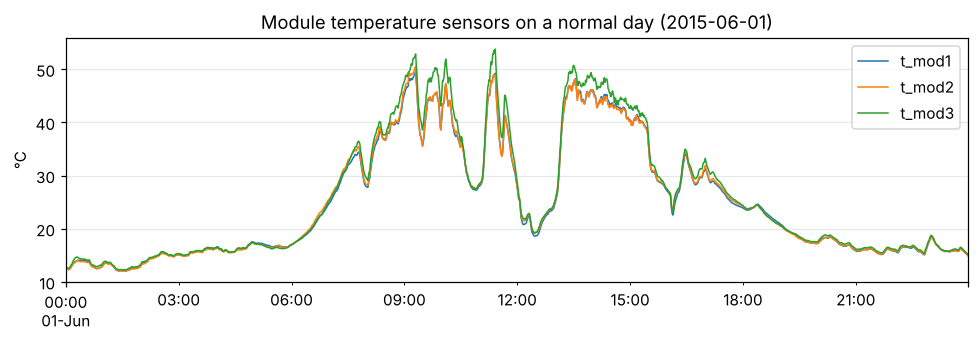

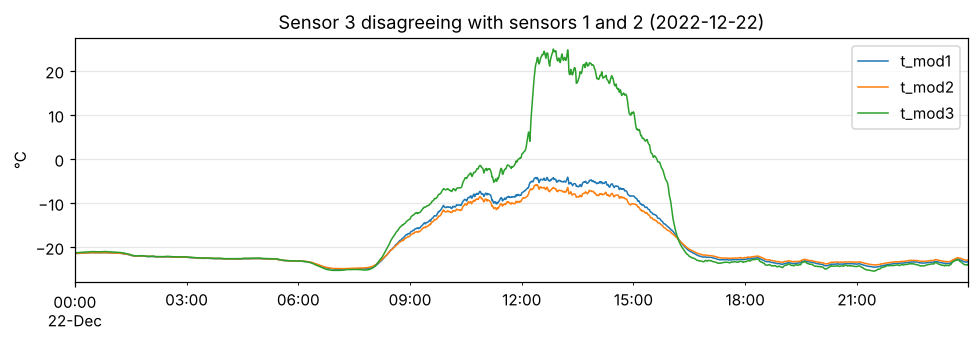

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.2))
d = df.loc["2015-06-01", ["t_mod1", "t_mod2", "t_mod3"]].where(lambda x: x > -100)
d.plot(ax=ax, lw=1)
ax.set_ylabel("°C"); ax.set_title("Module temperature sensors on a normal day (2015-06-01)")
fig.tight_layout()

bad_day = qc.flag_module_temp_disagreement(df)["t_mod3"].groupby(df.index.date).sum().idxmax()
fig, ax = plt.subplots(figsize=(9, 3.2))
df.loc[str(bad_day), ["t_mod1", "t_mod2", "t_mod3"]].where(lambda x: x > -100).plot(ax=ax, lw=1)
ax.set_ylabel("°C"); ax.set_title(f"Sensor 3 disagreeing with sensors 1 and 2 ({bad_day})")
fig.tight_layout(); fig.savefig(FIG / "02_module_temp_disagreement.png")

## 5. A one-year outage hidden in a "complete" record

Monthly energy from the inverter compared with the irradiance on the array tells the story.

,AC energy (kWh),POA insolation (kWh/m²)
2016-10-01,147.100006,188.000000
2016-11-01,128.899994,164.100006
2016-12-01,39.700001,144.199997
2017-01-01,0.900000,129.300003
2017-02-01,0.900000,139.800003
2017-03-01,1.100000,172.800003
2017-04-01,1.200000,187.800003
2017-05-01,1.400000,175.600006
2017-06-01,1.400000,178.600006
2017-07-01,1.400000,168.300003


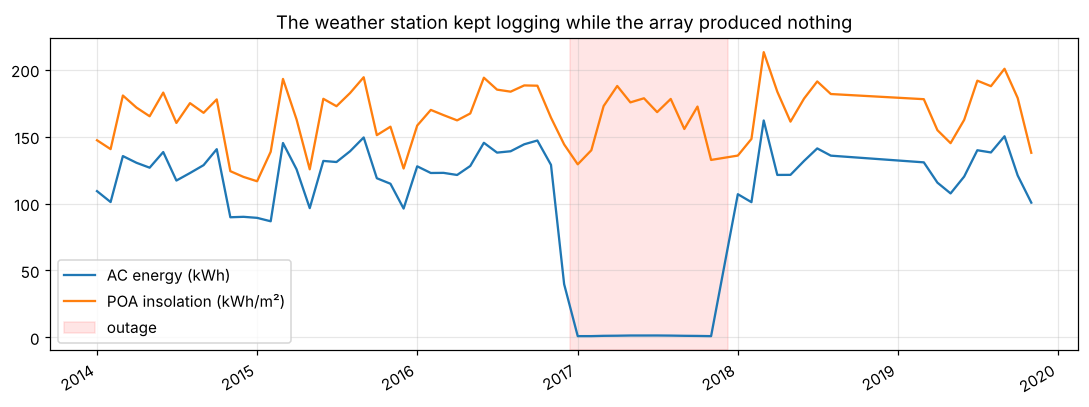

In [8]:
ac_day = df.ac_power.where(solar.elevation > 0).clip(lower=0)
monthly = pd.DataFrame({
    "AC energy (kWh)": ac_day.resample("MS").sum() / 60 / 1000,
    "POA insolation (kWh/m²)": df.poa.where(df.poa > -50).clip(lower=0).resample("MS").sum() / 60 / 1000,
})
coverage = df.poa.notna().resample("MS").mean()
monthly = monthly[coverage > 0.8]   # hide months that are mostly missing data
fig, ax = plt.subplots(figsize=(10, 3.8))
monthly.loc["2014":"2019"].plot(ax=ax, lw=1.5)
ax.axvspan("2016-12-15", "2017-12-10", color="red", alpha=0.1, label="outage")
ax.set_title("The weather station kept logging while the array produced nothing")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "03_outage.png")
monthly.loc["2016-10":"2018-01"].round(1)

In [9]:
outage = qc.flag_no_output_in_sun(df.ac_power, clean.poa)
by_month = outage.resample("MS").sum() / 60
print(f"Sunny hours with no output: {outage.sum()/60:,.0f} h in total")
print(f"of which Dec 2016 – Dec 2017: {outage['2016-12':'2017-12'].sum()/60:,.0f} h")
by_month[by_month > 5].round(0)

Sunny hours with no output: 3,386 h in total
of which Dec 2016 – Dec 2017: 2,696 h


2011-01-01      9.0
2011-12-01      6.0
2012-01-01      6.0
2012-07-01     22.0
2013-02-01     13.0
2013-03-01     23.0
2013-04-01     30.0
2013-05-01      8.0
2013-12-01     29.0
2014-01-01     11.0
2014-02-01      8.0
2014-03-01      5.0
2014-08-01     21.0
2014-11-01     14.0
2014-12-01      7.0
2015-01-01      5.0
2015-02-01     40.0
2015-03-01      8.0
2015-11-01      7.0
2015-12-01      8.0
2016-02-01     16.0
2016-03-01     13.0
2016-04-01      8.0
2016-12-01    136.0
2017-01-01    183.0
2017-02-01    187.0
2017-03-01    228.0
2017-04-01    259.0
2017-05-01    255.0
2017-06-01    263.0
2017-07-01    244.0
2017-08-01    249.0
2017-09-01    217.0
2017-10-01    232.0
2017-11-01    183.0
2017-12-01     59.0
2018-02-01     16.0
2018-04-01     35.0
2019-03-01      6.0
2019-10-01     22.0
2019-11-01      8.0
2020-02-01     13.0
2020-03-01      5.0
2020-04-01     13.0
2021-04-01     10.0
2022-01-01      5.0
2022-02-01     29.0
2022-03-01     13.0
2022-07-01     67.0
2022-11-01     10.0


From mid-December 2016 to early December 2017 the DC side reads zero and the AC meter shows only
the inverter's ~3 W standby draw, while the irradiance and temperature sensors keep working. Every
row exists, so a simple "missing values" check would call that year complete. Without the
*no-output-in-sunlight* check, this year would enter the degradation analysis as a 99 % performance
loss.

The rest of the no-output hours are short events, mostly in winter (e.g. February 2015), which is
consistent with snow covering a 40° array after storms, plus a few multi-day trips such as July 2022.

## 6. Night-time offsets

In [10]:
qc.night_offsets(df, solar.elevation).round(2)

,ac_power,dc_power,poa
2010,0.36,0.01,-2.84
2011,3.27,0.00,-2.80
2012,3.18,0.01,-2.86
2013,2.83,0.01,-2.74
2014,2.84,0.01,-2.83
2015,2.86,0.01,-2.82
2016,2.87,0.01,-2.88
2017,3.08,0.01,-3.12
2018,2.87,0.01,-2.94
2019,2.88,0.01,-2.89


* The **POA pyranometer reads about −3 W/m² at night**, the typical thermal offset of a thermopile
  sensor. It is small but is removed by clipping at zero for energy totals.
* The **AC power channel reads about +3 W at night** from 2011 onward: the meter records the
  inverter's standby consumption as a positive value. Over a year this adds ~13 kWh of phantom
  "production" (just under 1 % of the ~1,500 kWh the array makes in a full year) if nights are not excluded.
* DC power correctly reads 0.

## 7. Timestamp check against the sun

Logger clocks drift, and daylight-saving shifts are a classic source of error. On clear days the
measured POA profile should line up with the modelled clear-sky profile. For each clear day the shift
(in minutes) that best aligns the two is found by cross-correlation.

788 clear days found


,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
median shift (min),-9.0,-8.0,-7.0,-9.0,-9.0,-9.0,-9.0,-9.0,-9.0,-9.0,-8.0,-9.0,-9.0,-9.0
clear days,12.0,75.0,81.0,65.0,57.0,60.0,88.0,59.0,51.0,44.0,35.0,69.0,78.0,9.0


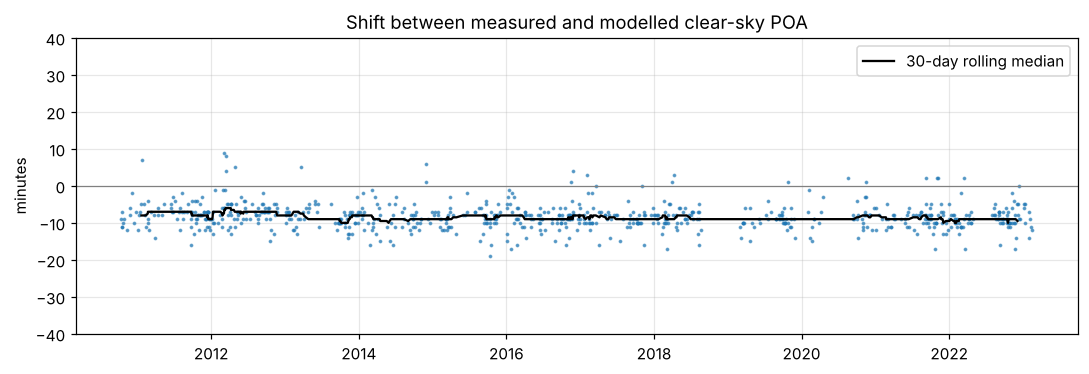

In [11]:
cdays = qc.clear_days(clean.poa, solar.poa_clearsky)
in_clear = pd.Index(clean.index.normalize()).isin(cdays)
offset = qc.daily_clock_offset(clean.poa[in_clear], solar.poa_clearsky[in_clear])
print(f"{len(cdays)} clear days found")
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(offset.index, offset, ".", ms=3, alpha=0.6)
ax.plot(offset.rolling(30, center=True).median(), color="k", lw=1.5, label="30-day rolling median")
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylim(-40, 40); ax.set_ylabel("minutes"); ax.legend()
ax.set_title("Shift between measured and modelled clear-sky POA")
fig.tight_layout(); fig.savefig(FIG / "04_clock_check.png")
pd.DataFrame({"median shift (min)": offset.groupby(offset.index.year).median(),
              "clear days": offset.groupby(offset.index.year).size()}).T

In [12]:
offset.groupby(offset.index.month).median().to_frame("median shift by month (min)").T

,1,2,3,4,5,6,7,8,9,10,11,12
median shift by month (min),-8.0,-10.0,-9.0,-8.0,-8.0,-8.0,-8.0,-8.0,-9.0,-10.0,-8.0,-8.0


The measured profile runs about **8–9 minutes earlier than the model, every year and every month**.
This gives three conclusions:

* There is **no clock drift**.
* There is **no daylight-saving jump**. A DST error would show up as a 60-minute shift in summer only.
* There is a **constant offset**. It may come from the logger clock or timestamp convention, or from the
  array facing a few degrees east of the 180° in the metadata. Because it is constant, it does not affect
  daily energy or the degradation trend.

## 8. Save the cleaned data

In [13]:
clean.to_parquet(ROOT / "data/system4_clean.parquet")
solar.to_parquet(ROOT / "data/solar.parquet")
pd.Series(cdays, name="date").to_csv(RES / "clear_days.csv", index=False)
summary = counts.astype(int)
summary.to_csv(RES / "qc_flag_counts.csv")
usable = clean[["ac_power", "poa", "t_mod"]].notna().all(axis=1) & (solar.elevation > 5)
print(f"Daylight minutes usable for performance analysis: {usable.sum():,} "
      f"of {(solar.elevation > 5).sum():,} ({usable.sum()/(solar.elevation > 5).sum():.1%})")

Daylight minutes usable for performance analysis: 2,362,172 of 3,193,248 (74.0%)
